In [1]:

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter

In [2]:
import os
import re
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths:
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [3]:
df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [4]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/2428668717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [5]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
# if 'NACCUDSD' in post.columns:
#     dem_events_all = post[post['NACCUDSD'] == 4].copy()
#     dementia_def = 'NACCUDSD==4'
# else:
#     dem_events_all = post[post['DEMENTED'] == 1].copy()
#     dementia_def = 'DEMENTED==1'

def get_dementia_events(df_in):
    if "DEMENTED" in df_in.columns:
        return df_in[df_in["DEMENTED"] == 1].copy(), "DEMENTED==1"
    elif "NACCUDSD" in df_in.columns:
        return df_in[df_in["NACCUDSD"] == 4].copy(), "NACCUDSD==4"
    else:
        raise KeyError("Neither DEMENTED nor NACCUDSD found.")
    

dem_events_all, dementia_def = get_dementia_events(post)
first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474

=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: DEMENTED==1
Participants with ANY post-baseline dementia event: 5502


/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/2108224931.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [101]:
# def subtype_primary(row):
#     # Alzheimer's disease
#     if "NACCALZD" in row and row["NACCALZD"] == 1:
#         return "AD"

#     # Lewy body disease
#     if "NACCLBDE" in row and row["NACCLBDE"] == 1:
#         return "PD_LBD"

#     # Vascular brain injury
#     if "CVD" in row and row["CVD"] == 1:
#         return "Vascular"

#     return "Other/Unk"


# def subtype_anymention(row):
#     if ("NACCALZD" in row and row["NACCALZD"] == 1):
#         return "AD"

#     if ("NACCLBDE" in row and row["NACCLBDE"] == 1):
#         return "PD_LBD"

#     if ("CVD" in row and row["CVD"] == 1):
#         return "Vascular"

#     return "Other/Unk"


# def subtype_contributing(row):
#     if "NACCALZP" in row and row["NACCALZP"] in [1,2]:
#         return "AD"

#     if "NACCLBDP" in row and row["NACCLBDP"] in [1,2]:
#         return "PD_LBD"

#     if "CVDIF" in row and row["CVDIF"] in [1,2]:
#         return "Vascular"

#     return "Other/Unk"

In [102]:
# first_dem_ever["subtype_primary"] = first_dem_ever.apply(subtype_primary, axis=1)
# first_dem_ever["subtype_any"]     = first_dem_ever.apply(subtype_anymention, axis=1)
# first_dem_ever["subtype_contrib"] = first_dem_ever.apply(subtype_contributing, axis=1)

# first_dem_ever["subtype_primary_contrib"] = np.where(
#     first_dem_ever["subtype_primary"].eq("Other/Unk"),
#     first_dem_ever["subtype_contrib"],
#     first_dem_ever["subtype_primary"],
# )

# first_dem_ever["subtype_primary_contrib_any"] = np.where(
#     first_dem_ever["subtype_primary_contrib"].eq("Other/Unk"),
#     first_dem_ever["subtype_any"],
#     first_dem_ever["subtype_primary_contrib"],
# )

In [6]:
def subtype_primary(row):

    formver = row.get("FORMVER", np.nan)

    # PD / LBD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 2:
        return "PD_LBD"

    # Vascular
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 8:
        return "Vascular"

    # AD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 1:
        return "AD"

    return "Other/Unk"


# Stage 1: Primary
first_dem_ever["subtype_primary_contrib_any"] = first_dem_ever.apply(subtype_primary, axis=1)


print("\nFinal (Primary -> Contrib -> Any) subtype counts:")
display(first_dem_ever["subtype_primary_contrib_any"].value_counts())


Final (Primary -> Contrib -> Any) subtype counts:


subtype_primary_contrib_any
AD           4218
Other/Unk     651
PD_LBD        374
Vascular      259
Name: count, dtype: int64

In [7]:
# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4218
Other/Unk      651
PD_LBD         374
Vascular       259
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [8]:
surv = surv[surv["time_to_event"] > 0].copy()

In [9]:
surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()
print(surv_main["event_type"].value_counts())

event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64


In [10]:
surv["event_any_dementia"] = (surv["event_observed"] == 1).astype(int)

In [11]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27052
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_any_dementia
0    22201
1     4851
Name: count, dtype: int64


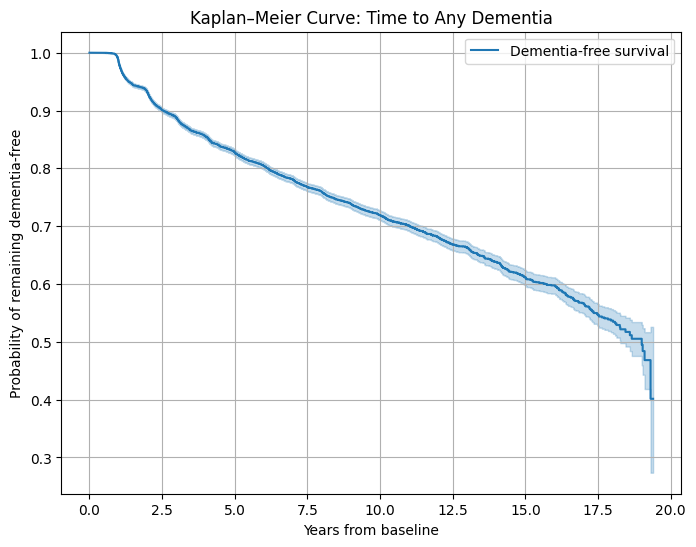

In [12]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
plt.show()

In [13]:
# cox_features = [
#     "NACCAGE",     
#     "SEX",
#     "EDUC",
#     "NACCMMSE",     
#     "CDRSUM",
#     "DIABETES",
#     "HYPERTEN",
#     "HYPERCHO",
#     "CBSTROKE",
#     "CVAFIB",
#     "DEP2YRS",
#     "APNEA"
# ]


cox_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMS",
    "CDRSUM",
    "DEP2YRS",

    # vascular
    "CBSTROKE",
    "HYPERTEN",
    "DIABET",
    "HYPERCHO",
    "AFIBRILL",
    "CVDSIGNS",

    # metabolic / sleep
    "SLEEPAP",

    # functional status
    "POSTINST"
]

In [14]:

baseline_full = (
    df[df["NACCID"].isin(baseline["NACCID"])]
    .sort_values(["NACCID", "visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

print("Baseline rows with predictors:", len(baseline_full))
baseline_full.head()

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/3673114531.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline rows with predictors: 38341


,NACCID,NACCADC,PACKET,FORMVER,VISITMO,VISITDAY,VISITYR,NACCVNUM,NACCAVST,NACCNVST,NACCDAYS,NACCFDYS,NACCCORE,NACCREAS,NACCREFR,BIRTHMO,BIRTHYR,SEX,HISPANIC,HISPOR,HISPORX,RACE,RACEX,RACESEC,RACESECX,RACETER,RACETERX,PRIMLANG,PRIMLANX,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,INBIRMO,INBIRYR,INSEX,NEWINF,INHISP,INHISPOR,INHISPOX,NACCNINR,INRACE,INRACEX,INRASEC,INRASECX,INRATER,INRATERX,INEDUC,INRELTO,INRELTOX,INKNOWN,INLIVWTH,INVISITS,INCALLS,INRELY,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMX,NACCAMS,NACCAMSX,NACCFM,NACCFMX,NACCFMS,NACCFMSX,NACCOM,NACCOMX,NACCOMS,NACCOMSX,NACCFADM,NACCFFTD,ANYMEDS,DRUG1,DRUG2,DRUG3,DRUG4,DRUG5,DRUG6,DRUG7,DRUG8,DRUG9,DRUG10,DRUG11,DRUG12,DRUG13,DRUG14,DRUG15,DRUG16,DRUG17,DRUG18,DRUG19,DRUG20,DRUG21,DRUG22,DRUG23,DRUG24,DRUG25,...,NPFTD,NPFTDTDP,NPALSMND,NPOFTD,NPOFTD1,NPOFTD2,NPOFTD3,NPOFTD4,NPOFTD5,NPFTDNO,NPFTDSPC,NPTDPA,NPTDPB,NPTDPC,NPTDPD,NPTDPE,NPPDXA,NPPDXB,NACCPRIO,NPPDXD,NPPDXE,NPPDXF,NPPDXG,NPPDXH,NPPDXI,NPPDXJ,NPPDXK,NPPDXL,NPPDXM,NPPDXN,NACCDOWN,NPPDXP,NPPDXQ,NACCOTHP,NACCWRI1,NACCWRI2,NACCWRI3,NACCBNKF,NPBNKB,NACCFORM,NACCPARA,NACCCSFP,NPBNKF,NPFAUT,NPFAUT1,NPFAUT2,NPFAUT3,NPFAUT4,NACCDAGE,NACCINT,NPNIT,NPCERAD,NPADRDA,NPOCRIT,NPVOTH,NPLEWYCS,NPGENE,NPFHSPEC,NPTAUHAP,NPPRNP,NPCHROM,NPPNORM,NPCNORM,NPPADP,NPCADP,NPPAD,NPCAD,NPPLEWY,NPCLEWY,NPPVASC,NPCVASC,NPPFTLD,NPCFTLD,NPPHIPP,NPCHIPP,NPPPRION,NPCPRION,NPPOTH1,NPCOTH1,NPOTH1X,NPPOTH2,NPCOTH2,NPOTH2X,NPPOTH3,NPCOTH3,NPOTH3X,NPARTAG,NPATGSEV,NPATGAMY,NPATGAM1,NPATGAM2,NPATGAM3,NPATGAM4,NPATGAM5,NPATGFRN,NPATGFR1,NPATGFR2,NPATGFR3,NPATGFR4,visit_date
0,NACC000011,1416,I,1.0,4,17,2006,1,4,4,1204,0,1,1,8,2,1944,2,0,88,None,1,None,88,None,88,None,1,None,16,1,2,1,1,2,10,1930,1,-4,0,88,None,1,1,None,88,None,88,None,12,5,None,-4,0,2,1,0,9,9,9,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,CONJUGATED ESTROGENS,CALCIUM-VITAMIN D,CALCIUM-VITAMIN D,MULTIVITAMIN,GLUCOSAMINE,UBIQUINONE,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2006-04-17
1,NACC000034,9661,I,3.0,7,16,2015,1,7,6,2552,0,1,1,1,8,1935,2,0,88,None,1,None,88,None,88,None,1,None,15,2,1,1,1,2,1,1960,2,-4,0,88,None,1,1,None,88,None,88,None,12,2,None,55,0,5,3,0,1,1,1,0,None,-4,None,0,None,-4,None,0,None,-4,None,0,0,1,ATENOLOL,ASPIRIN,LEVOTHYROXINE,OMEGA-3 POLYUNSATURATED FATTY ACIDS,LISINOPRIL,CHOLECALCIFEROL,CALCIUM-VITAMIN D,MULTIVITAMIN,FLAX,MULTIVITAMIN,MULTIVITAMIN WITH MINERALS,ZINC SULFATE,DONEPEZIL,FLAX,UBIQUINONE,BIFIDOBACTERIUM-LACTOBACILLUS,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,-4,-4,-4,-4,None,None,None,None,888,888,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,-4.0,None,-4.0,-4.0,None,-4.0,-4.0,None,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,2015-07-16
2,NACC000067,2096,I,2.0,5,23,2012,1,3,3,763,0,1,1,2,4,1952,1,0,88,None,1,None,88,None,88,None,1,None,18,1,2,2,1,1,1,1948,2,-4,0,88,None,1,1,None,88,None,88,None,16,1,None,-4,1,8,8,0,1,1,0,-4,None,-4,None,-4,None,-4,None,-4,None,-4,None,0,0,1,LORAZEPAM,CHOLESTYRAMINE,DOXEPIN,CYANOCOBALAMIN,ZOLPIDEM,LOPERAMIDE,ACETAMINOPHEN-HYDROCODONE,CARBIDOPA-LEVODOPA,TIMOLOL OPHTHALMIC,BRIMONIDINE OPHTHALMIC,TESTOSTERONE TOPICAL,CITALOPRAM,BIMATOPROST OPHTHALMIC,BIMATOPROST OPHTHALMIC,MELATONIN,CITALOPRAM,None,None,None,None,None,None,None,None,None,...,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,None,None,None,-4,-4,-4,

In [15]:
baseline_features = baseline_full[["NACCID"] + [c for c in cox_features if c in baseline_full.columns]].copy()

# Merging into survival dataframe
cox_df = surv_main.merge(baseline_features, on="NACCID", how="left")

print("Rows after merge:", len(cox_df))
cox_df.head()

Rows after merge: 27052


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,EDUC,CDRSUM,DEP2YRS,CBSTROKE,HYPERTEN,DIABET,HYPERCHO,AFIBRILL,CVDSIGNS,SLEEPAP,POSTINST
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62,2,16,0.5,0,0,0,-4.0,0,-4.0,-4.0,-4.0,-4.0
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79,2,15,0.5,0,0,1,0.0,0,0.0,0.0,0.0,0.0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60,1,18,0.5,1,0,0,-4.0,0,-4.0,-4.0,-4.0,-4.0
3,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored,0,54,2,16,0.0,0,0,0,0.0,0,0.0,0.0,0.0,0.0
4,NACC000144,2010-08-17,8.487337,NaT,NaN,NaN,0,8.487337,Censored,0,79,1,18,0.0,1,0,1,-4.0,1,-4.0,-4.0,-4.0,-4.0


In [16]:
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

In [17]:
model_cols = ["time_to_event", "event_any_dementia"] + [c for c in cox_features if c in cox_df.columns]
cox_df_model = cox_df[model_cols].copy()

print(cox_df_model.columns.tolist())

['time_to_event', 'event_any_dementia', 'NACCAGE', 'SEX', 'EDUC', 'CDRSUM', 'DEP2YRS', 'CBSTROKE', 'HYPERTEN', 'DIABET', 'HYPERCHO', 'AFIBRILL', 'CVDSIGNS', 'SLEEPAP', 'POSTINST']


In [18]:
for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if cox_df_model[col].dtype.kind in "biufc":
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())
    else:
        mode_vals = cox_df_model[col].mode()
        if len(mode_vals) > 0:
            cox_df_model[col] = cox_df_model[col].fillna(mode_vals.iloc[0])

In [19]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))

Final Cox rows: 27052


In [20]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27052 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27052
number of events observed = 4851
   partial log-likelihood = -43585.60
         time fit was run = 2026-03-10 05:18:31 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
NACCAGE    0.03      1.03      0.00            0.03            0.04                1.03                1.04
SEX       -0.16      0.85      0.02           -0.21           -0.12                0.81                0.89
EDUC      -0.00      1.00      0.00           -0.01            0.00                0.99                1.00
CDRSUM     0.55      1.74      0.01            0.54            0.57                1.71                1.76
DEP2YRS    0.06      1.06      0.01            0.04            0.08                1.04                1.09
CBSTROKE   0.03      1.03      0.02           -0.00            0.07                1.00                1.07
HYPERTEN  -0.00      1.00      0.01           -0.03            0.02                0.97                1.03
DIABET    -0.01      0.99      0.01           -0.02            0.01                0.98                1.01
HYPERCHO   0.00      1.00      0.01           -0.02            0.03                0.98                1.03
AFIBRILL  -0.00      1.00      0.01           -0.02            0.01                0.98                1.01
CVDSIGNS  -0.00      1.00      0.01           -0.02            0.02                0.98                1.02
SLEEPAP   -0.01      0.99      0.01           -0.02            0.01                0.98                1.01
POSTINST   0.01      1.01      0.01           -0.01            0.02                0.99                1.02

           cmp to     z      p  -log2(p)
covariate                               
NACCAGE      0.00 27.15 <0.005    536.96
SEX          0.00 -7.02 <0.005     38.75
EDUC         0.00 -1.30   0.19      2.38
CDRSUM       0.00 74.37 <0.005       inf
DEP2YRS      0.00  5.20 <0.005     22.22
CBSTROKE     0.00  1.74   0.08      3.61
HYPERTEN     0.00 -0.28   0.78      0.36
DIABET       0.00 -0.83   0.40      1.31
HYPERCHO     0.00  0.41   0.68      0.55
AFIBRILL     0.00 -0.46   0.64      0.64
CVDSIGNS     0.00 -0.04   0.97      0.05
SLEEPAP      0.00 -1.22   0.22      2.16
POSTINST     0.00  0.81   0.42      1.26
---
Concordance = 0.85
Partial AIC = 87197.19
log-likelihood ratio test = 4354.52 on 13 df
-log2(p) of ll-ratio test = inf

In [21]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDRSUM,0.551240,1.735403,0.007412,0.000000e+00
NACCAGE,0.033875,1.034455,0.001248,2.291873e-162
SEX,-0.163858,0.848863,0.023328,2.155885e-12
DEP2YRS,0.061339,1.063259,0.011806,2.040702e-07
CBSTROKE,0.030651,1.031125,0.017631,8.213383e-02
EDUC,-0.002621,0.997383,0.002011,1.925206e-01
SLEEPAP,-0.008630,0.991407,0.007100,2.241822e-01
DIABET,-0.006360,0.993661,0.007629,4.044853e-01
POSTINST,0.006928,1.006952,0.008532,4.168241e-01


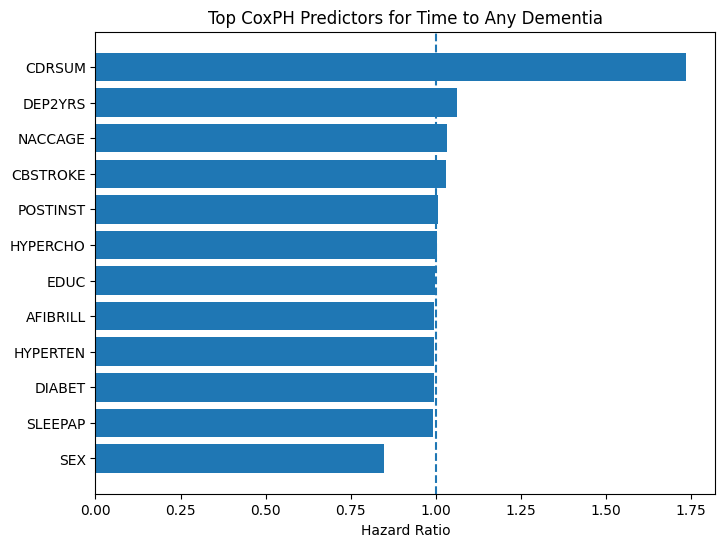

In [22]:
import matplotlib.pyplot as plt

top_hr = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

plt.figure(figsize=(8,6))
plt.barh(top_hr.index.astype(str), top_hr["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
plt.show()

In [23]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'SEX' failed the non-proportional test: p-value is 0.0197.

   Advice: with so few unique values (only 2), you can include `strata=['SEX', ...]` in the call in
`.fit`. See documentation in link [E] below.

3. Variable 'CDRSUM' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'CDRSUM' might b

[]

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter, AalenJohansenFitter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [25]:
# master modeling dataframe

# Starting from cox_df (already merged with baseline features)
model_df = cox_df.copy()

# Binary event
model_df["event_any_dementia"] = (model_df["event_type"] != "Censored").astype(int)

# Keeping only rows with valid time
model_df = model_df[
    model_df["time_to_event"].notna() &
    (model_df["time_to_event"] > 0)
].copy()

print("model_df shape:", model_df.shape)
print(model_df["event_type"].value_counts(dropna=False))

model_df shape: (27052, 23)
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64


In [26]:
# competing risk event coding:
# 0 = censored
# 1 = AD
# 2 = PD_LBD
# 3 = Vascular

event_code_map = {
    "Censored": 0,
    "AD": 1,
    "PD_LBD": 2,
    "Vascular": 3
}

cr_df = model_df[model_df["event_type"].isin(event_code_map.keys())].copy()
cr_df["event_code"] = cr_df["event_type"].map(event_code_map).astype(int)

print(cr_df["event_type"].value_counts())
print(cr_df["event_code"].value_counts())

event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_code
0    22201
1     4218
2      374
3      259
Name: count, dtype: int64


Cell 124 — Cumulative incidence curves (Aalen-Johansen)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lifelines/fitters/aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


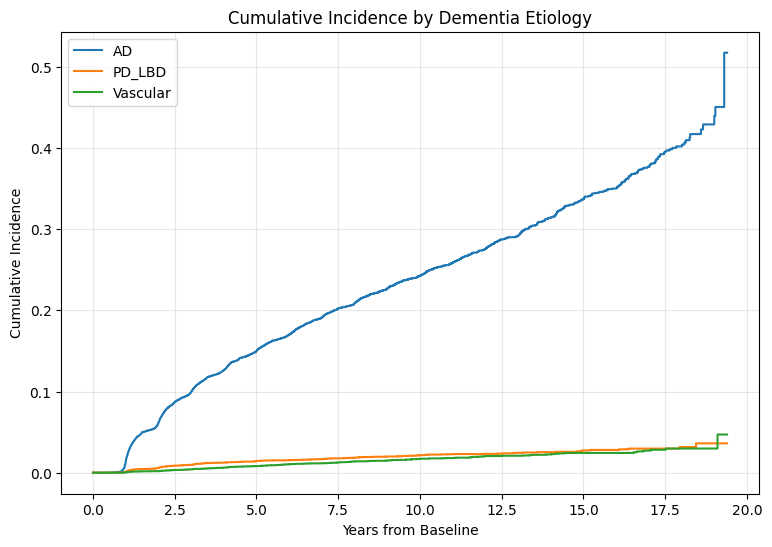

In [27]:
# cumulative incidence curves for competing risks

plt.figure(figsize=(9, 6))

for event_name, event_code in [("AD", 1), ("PD_LBD", 2), ("Vascular", 3)]:
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )
    ajf.plot(ci_show=False)

plt.title("Cumulative Incidence by Dementia Etiology")
plt.xlabel("Years from Baseline")
plt.ylabel("Cumulative Incidence")
plt.grid(True, alpha=0.3)
plt.legend(["AD", "PD_LBD", "Vascular"])
plt.show()

2) cause-specific cox model
Cell 125 — Helper to fit cause-specific Cox

In [28]:
# cause-specific cox helper

def fit_cause_specific_cox(df, event_name, features, penalizer=0.1):
    tmp = df.copy()
    tmp["event_cs"] = (tmp["event_type"] == event_name).astype(int)

    use_cols = ["time_to_event", "event_cs"] + [c for c in features if c in tmp.columns]
    tmp = tmp[use_cols].copy()

    for col in tmp.columns:
        if col in ["time_to_event", "event_cs"]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    # one-hot encoding categorical
    cat_cols = [c for c in tmp.columns if c not in ["time_to_event", "event_cs"] and not pd.api.types.is_numeric_dtype(tmp[c])]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(tmp, duration_col="time_to_event", event_col="event_cs")
    return cph, tmp

Cell 126 — Run cause-specific Cox for AD / PD_LBD / Vascular

In [29]:
# cause-specific cox models

cause_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS"
]

cause_models = {}
cause_dfs = {}

for outcome in ["AD", "PD_LBD", "Vascular"]:
    cph, tmp_df = fit_cause_specific_cox(model_df, outcome, cause_features, penalizer=0.1)
    cause_models[outcome] = cph
    cause_dfs[outcome] = tmp_df

    print("\n" + "=" * 70)
    print(f"CAUSE-SPECIFIC COX FOR: {outcome}")
    print("=" * 70)
    display(
        cph.summary[["coef", "exp(coef)", "se(coef)", "p"]]
        .sort_values("p")
        .head(15)
    )


CAUSE-SPECIFIC COX FOR: AD


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.539950,1.715921,0.008028,0.000000e+00
NACCAGE,0.032749,1.033292,0.001291,6.876291e-142
SEX,-0.097079,0.907485,0.024430,7.075670e-05
DEP2YRS,0.044799,1.045818,0.012745,4.395773e-04
EDUC,-0.003822,0.996185,0.002124,7.194292e-02
HYPERCHO,0.002086,1.002088,0.011502,8.561104e-01
CBSTROKE,0.002057,1.002059,0.019848,9.174655e-01
HYPERTEN,-0.001442,0.998559,0.015446,9.256220e-01



CAUSE-SPECIFIC COX FOR: PD_LBD


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.180052,1.197279,0.018924,1.822417e-21
SEX,-0.193512,0.824060,0.036718,1.363068e-07
DEP2YRS,0.033325,1.033886,0.019656,8.999432e-02
NACCAGE,0.001891,1.001893,0.001812,2.967759e-01
EDUC,0.002212,1.002215,0.002877,4.418997e-01
HYPERTEN,-0.013295,0.986793,0.022834,5.603906e-01
HYPERCHO,-0.004659,0.995352,0.017226,7.867980e-01
CBSTROKE,0.006854,1.006878,0.031362,8.270016e-01



CAUSE-SPECIFIC COX FOR: Vascular


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.079658,1.082917,0.019582,0.000047
NACCAGE,0.007325,1.007352,0.001850,0.000075
CBSTROKE,0.112156,1.118687,0.030619,0.000249
HYPERTEN,0.031053,1.031540,0.022885,0.174808
DEP2YRS,0.024251,1.024547,0.020078,0.227121
HYPERCHO,0.015092,1.015207,0.017372,0.384977
SEX,-0.031204,0.969278,0.037498,0.405331
EDUC,-0.001716,0.998285,0.002969,0.563231


Cell 30 — Plot top hazard ratios for each cause-specific model

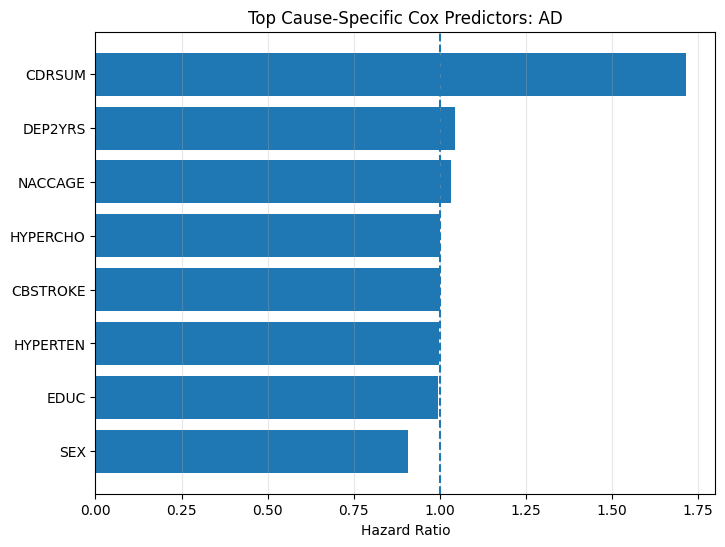

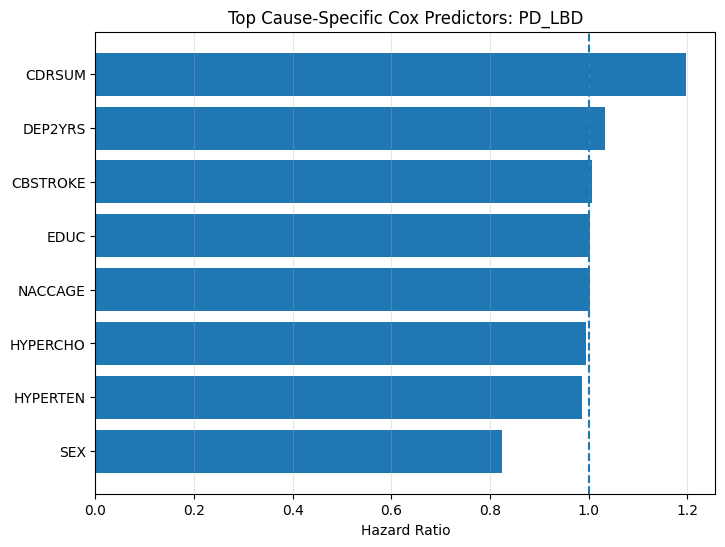

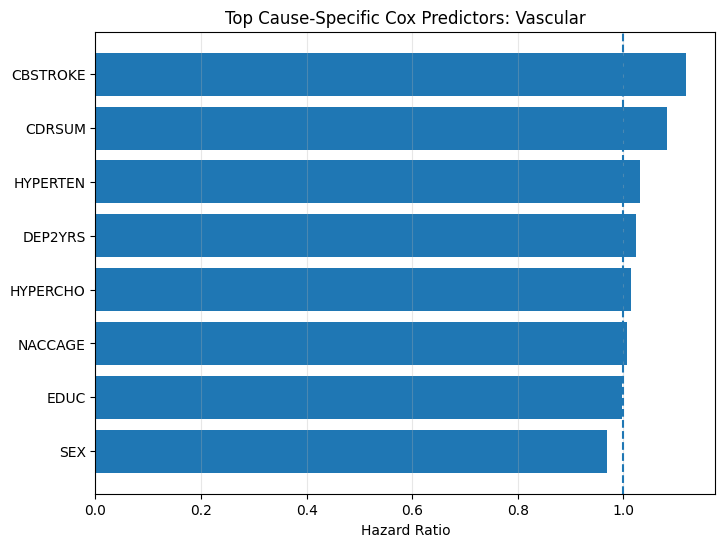

In [30]:
# top HR plots for each etiology

for outcome, cph in cause_models.items():
    hr_table = cph.summary[["exp(coef)", "p"]].copy()
    hr_table = hr_table.rename(columns={"exp(coef)": "hazard_ratio", "p": "p_value"})
    hr_table = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

    plt.figure(figsize=(8, 6))
    plt.barh(hr_table.index.astype(str), hr_table["hazard_ratio"])
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("Hazard Ratio")
    plt.title(f"Top Cause-Specific Cox Predictors: {outcome}")
    plt.grid(True, axis="x", alpha=0.3)
    plt.show()

3) vascular burden index

Cell 128 — Building vascular burden index

In [31]:
# vascular burden index

vascular_candidates = [
    "CBSTROKE",   # stroke
    "HYPERTEN",   # HTN
    "DIABETES",   # diabetes
    "HYPERCHO",   # hypercholesterolemia
    "CVAFIB",     # afib
    "CVCHF",      # CHF if present
    "CBTIA",      # TIA if present
    "BPSYS",      # systolic BP if present
    "BPDIAS",     # diastolic BP if present
    "SMOKYRS",    # smoking years if present
    "PACKSPER"    # smoking intensity if present
]

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("vascular_features:", vascular_features)

# Defining target: vascular dementia vs everyone else
vbi_df = model_df.copy()
vbi_df["vascular_target"] = (vbi_df["event_type"] == "Vascular").astype(int)

X_vbi = vbi_df[vascular_features].copy()
y_vbi = vbi_df["vascular_target"].copy()

# Filling in the missing
for col in X_vbi.columns:
    if pd.api.types.is_numeric_dtype(X_vbi[col]):
        X_vbi[col] = X_vbi[col].fillna(X_vbi[col].median())
    else:
        mode_vals = X_vbi[col].mode()
        if len(mode_vals) > 0:
            X_vbi[col] = X_vbi[col].fillna(mode_vals.iloc[0])

cat_cols = [c for c in X_vbi.columns if not pd.api.types.is_numeric_dtype(X_vbi[c])]
if len(cat_cols) > 0:
    X_vbi = pd.get_dummies(X_vbi, columns=cat_cols, drop_first=True)

vbi_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=RANDOM_STATE
)
vbi_model.fit(X_vbi, y_vbi)

# Probability = vascular burden index
vbi_df["vascular_burden_index"] = vbi_model.predict_proba(X_vbi)[:, 1]

print(vbi_df["vascular_burden_index"].describe())

vascular_features: ['CBSTROKE', 'HYPERTEN', 'HYPERCHO']
count    27052.000000
mean         0.442852
std          0.113319
min          0.000746
25%          0.345996
50%          0.473153
75%          0.499942
max          0.999999
Name: vascular_burden_index, dtype: float64


Cell 129 — Inspect vascular burden weights

In [32]:
# Inspect vascular burden model weights

vbi_coef = pd.DataFrame({
    "feature": X_vbi.columns,
    "coef": vbi_model.coef_[0]
}).sort_values("coef", ascending=False)

display(vbi_coef)

,feature,coef
0,CBSTROKE,1.004467
1,HYPERTEN,0.529194
2,HYPERCHO,0.107261


Cell 130 — Merging vascular burden into survival modeling

In [33]:
# add VBI into survival model

model_df = model_df.merge(
    vbi_df[["NACCID", "vascular_burden_index"]],
    on="NACCID",
    how="left"
)

if "vascular_burden_index_x" in model_df.columns:
    model_df["vascular_burden_index"] = model_df["vascular_burden_index_x"]
    drop_cols = [c for c in ["vascular_burden_index_x", "vascular_burden_index_y"] if c in model_df.columns]
    model_df = model_df.drop(columns=drop_cols)

print(model_df[["NACCID", "vascular_burden_index"]].head())

       NACCID  vascular_burden_index
0  NACC000011               0.345996
1  NACC000034               0.473153
2  NACC000067               0.345996
3  NACC000138               0.345996
4  NACC000144               0.499942


Cell 131 — Refitting any-dementia Cox with vascular burden index

In [34]:
# any-dementia cox + vascular burden index

cox_features_plus_vbi = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

cox_vbi_df = model_df[["time_to_event", "event_any_dementia"] + [c for c in cox_features_plus_vbi if c in model_df.columns]].copy()

for col in cox_vbi_df.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(cox_vbi_df[col]):
        cox_vbi_df[col] = cox_vbi_df[col].fillna(cox_vbi_df[col].median())
    else:
        mode_vals = cox_vbi_df[col].mode()
        if len(mode_vals) > 0:
            cox_vbi_df[col] = cox_vbi_df[col].fillna(mode_vals.iloc[0])

cat_cols = [c for c in cox_vbi_df.columns if c not in ["time_to_event", "event_any_dementia"] and not pd.api.types.is_numeric_dtype(cox_vbi_df[c])]
if len(cat_cols) > 0:
    cox_vbi_df = pd.get_dummies(cox_vbi_df, columns=cat_cols, drop_first=True)

cox_vbi = CoxPHFitter(penalizer=0.1)
cox_vbi.fit(cox_vbi_df, duration_col="time_to_event", event_col="event_any_dementia")

display(
    cox_vbi.summary[["coef", "exp(coef)", "se(coef)", "p"]]
    .sort_values("p")
    .head(20)
)

,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.551333,1.735565,0.007421,0.000000e+00
NACCAGE,0.033960,1.034543,0.001246,1.313404e-163
SEX,-0.163436,0.849221,0.023331,2.468531e-12
DEP2YRS,0.059603,1.061415,0.011730,3.747038e-07
vascular_burden_index,0.170699,1.186134,0.121825,1.611606e-01
EDUC,-0.002625,0.997379,0.002012,1.920474e-01
CBSTROKE,0.018831,1.019010,0.019564,3.357790e-01
HYPERTEN,-0.014076,0.986023,0.016297,3.877445e-01
HYPERCHO,0.000409,1.000409,0.011168,9.707710e-01


Cell 132 — Survival curves stratified by vascular burden tertiles

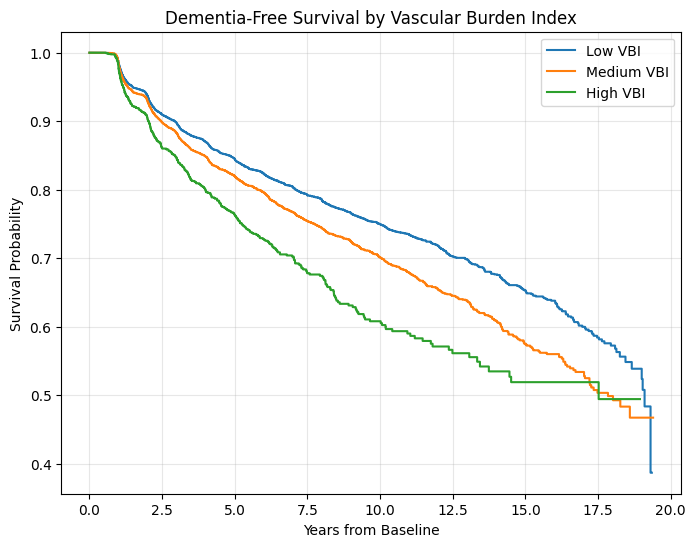

In [35]:
# kaplan-meier curves by vascular burden index tertiles

km_vbi_df = model_df[["time_to_event", "event_any_dementia", "vascular_burden_index"]].dropna().copy()
km_vbi_df["vbi_group"] = pd.qcut(
    km_vbi_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for grp in ["Low VBI", "Medium VBI", "High VBI"]:
    tmp = km_vbi_df[km_vbi_df["vbi_group"] == grp]
    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot(ci_show=False)

plt.title("Dementia-Free Survival by Vascular Burden Index")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

4) bootstrap uncertainty-aware survival prediction
Cell 133 — Bootstrap Cox ensemble


In [36]:
# Bootstrap Ensemble for uncertainty

N_BOOT = 30
PRED_HORIZON_YEARS = 5.0

boot_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

# Keeping NACCID only for tracking, not for model fitting
boot_df = model_df[["NACCID", "time_to_event", "event_any_dementia"] + [c for c in boot_features if c in model_df.columns]].copy()

# Filling missing values
for col in boot_df.columns:
    if col in ["NACCID", "time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(boot_df[col]):
        boot_df[col] = boot_df[col].fillna(boot_df[col].median())
    else:
        mode_vals = boot_df[col].mode()
        if len(mode_vals) > 0:
            boot_df[col] = boot_df[col].fillna(mode_vals.iloc[0])

# One-hot encode categorical columns
cat_cols = [
    c for c in boot_df.columns
    if c not in ["NACCID", "time_to_event", "event_any_dementia"]
    and not pd.api.types.is_numeric_dtype(boot_df[c])
]
if len(cat_cols) > 0:
    boot_df = pd.get_dummies(boot_df, columns=cat_cols, drop_first=True)

# The Columns actually used in Cox model
fit_cols = [c for c in boot_df.columns if c != "NACCID"]

boot_feature_cols = [
    c for c in fit_cols
    if c not in ["time_to_event", "event_any_dementia"]
]

risk_preds = []

for b in range(N_BOOT):
    sample_idx = np.random.choice(len(boot_df), size=len(boot_df), replace=True)

    boot_sample = boot_df.iloc[sample_idx][fit_cols].copy()

    cph_b = CoxPHFitter(penalizer=0.1)
    cph_b.fit(
        boot_sample,
        duration_col="time_to_event",
        event_col="event_any_dementia"
    )

    surv_funcs = cph_b.predict_survival_function(
        boot_df[boot_feature_cols],
        times=[PRED_HORIZON_YEARS]
    )

    risk_5y = 1.0 - surv_funcs.T.iloc[:, 0].values
    risk_preds.append(risk_5y)

risk_preds = np.vstack(risk_preds)

print("risk_preds shape:", risk_preds.shape)
print("n patients:", len(boot_df))
print("n feature cols:", len(boot_feature_cols))

risk_preds shape: (30, 27052)
n patients: 27052
n feature cols: 9


Cell 134 — Computing uncertainty + confidence

In [37]:
# uncertainty / confidence scores

uncertainty_df = boot_df[["NACCID", "time_to_event", "event_any_dementia"]].copy()
uncertainty_df["risk_5y_mean"] = risk_preds.mean(axis=0)
uncertainty_df["risk_5y_std"]  = risk_preds.std(axis=0)
uncertainty_df["risk_5y_p10"]  = np.percentile(risk_preds, 10, axis=0)
uncertainty_df["risk_5y_p90"]  = np.percentile(risk_preds, 90, axis=0)

# simple confidence score
max_std = uncertainty_df["risk_5y_std"].max()
uncertainty_df["confidence_score"] = 1 - (uncertainty_df["risk_5y_std"] / max_std)
uncertainty_df["confidence_score"] = uncertainty_df["confidence_score"].clip(0, 1)

display(uncertainty_df.head())
display(uncertainty_df.describe())

,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
0,NACC000011,3.296372,0,0.103452,0.002384,0.100505,0.106056,0.973489
1,NACC000034,5.848049,1,0.178003,0.003560,0.173898,0.181476,0.960418
2,NACC000067,2.088980,0,0.118997,0.004251,0.112897,0.124615,0.952738
3,NACC000138,1.043121,0,0.061207,0.001821,0.058239,0.063437,0.979757
4,NACC000144,8.487337,0,0.168799,0.006431,0.160375,0.174314,0.928502


,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
count,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000
mean,5.117712,0.179321,0.179370,0.006254,0.171615,0.187341,0.930469
std,4.214639,0.383628,0.134434,0.006615,0.128157,0.142158,0.073544
min,0.109514,0.000000,0.018644,0.000000,0.017134,0.019893,0.000000
25%,1.938398,0.000000,0.102829,0.002747,0.099211,0.106483,0.930065
50%,3.786448,0.000000,0.136843,0.004057,0.131017,0.141952,0.954887
75%,7.124572,0.000000,0.198948,0.006290,0.190241,0.206838,0.969455
max,19.392197,1.000000,1.000000,0.089940,1.000000,1.000000,1.000000


Cell 135 — Scatter plot: risk vs uncertainty

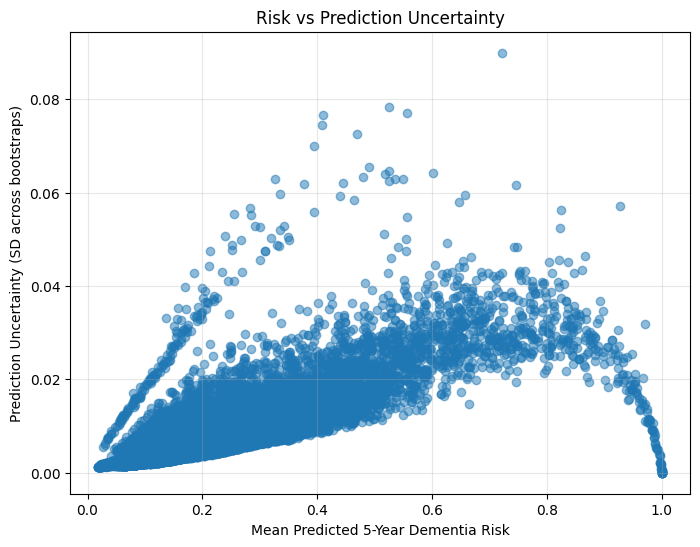

In [38]:
# risk vs uncertainty plot

plt.figure(figsize=(8, 6))
plt.scatter(
    uncertainty_df["risk_5y_mean"],
    uncertainty_df["risk_5y_std"],
    alpha=0.5
)
plt.xlabel("Mean Predicted 5-Year Dementia Risk")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Risk vs Prediction Uncertainty")
plt.grid(True, alpha=0.3)
plt.show()

Cell 136 — Identifying high-uncertainty cases

In [39]:
# flagging high-uncertainty cases

uncert_thresh = uncertainty_df["risk_5y_std"].quantile(0.80)
uncertainty_df["high_uncertainty"] = (uncertainty_df["risk_5y_std"] >= uncert_thresh).astype(int)

print("High-uncertainty threshold:", uncert_thresh)
print(uncertainty_df["high_uncertainty"].value_counts())

display(
    uncertainty_df.sort_values("risk_5y_std", ascending=False).head(15)
)

High-uncertainty threshold: 0.007293919582541299
high_uncertainty
0    21641
1     5411
Name: count, dtype: int64


,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score,high_uncertainty
16048,NACC592291,0.982888,0,0.722455,0.089940,0.605395,0.848948,0.000000,1
21743,NACC802578,0.958248,1,0.525545,0.078331,0.410670,0.633787,0.129075,1
19925,NACC733402,4.120465,0,0.556780,0.076998,0.441601,0.641806,0.143897,1
20016,NACC737136,2.847365,0,0.410234,0.076658,0.339354,0.480683,0.147679,1
11252,NACC417577,2.329911,1,0.408255,0.074394,0.319439,0.515466,0.172850,1
6405,NACC240534,1.023956,0,0.469920,0.072520,0.359763,0.555982,0.193682,1
3328,NACC124571,7.586585,0,0.394051,0.070058,0.307318,0.490115,0.221059,1
15233,NACC563150,2.491444,1,0.489860,0.065472,0.415003,0.577450,0.272049,1
21281,NACC784937,2.201232,1,0.524637,0.064544,0.443518,0.600810,0.282372,1
22491,NACC828932,1.070500,0,0.601498,0.064184,0.518006,0.671400,0.286370,1


5) uncertain-case phenotype analysis
Cell 137 — Merge uncertainty back to clinical variables

In [40]:
# merging uncertainty back for phenotype analysis

analysis_df = model_df.merge(
    uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score", "high_uncertainty"]],
    on="NACCID",
    how="left"
)

print(analysis_df.shape)

(27052, 28)


Cell 138 — Compare high- vs low-uncertainty groups

In [41]:
# phenotype comparison: high vs low uncertainty

compare_vars = [
    "NACCAGE",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

rows = []
for col in compare_vars:
    if col not in analysis_df.columns:
        continue

    tmp0 = analysis_df.loc[analysis_df["high_uncertainty"] == 0, col]
    tmp1 = analysis_df.loc[analysis_df["high_uncertainty"] == 1, col]

    rows.append({
        "variable": col,
        "low_uncert_mean": pd.to_numeric(tmp0, errors="coerce").mean(),
        "high_uncert_mean": pd.to_numeric(tmp1, errors="coerce").mean(),
        "difference": pd.to_numeric(tmp1, errors="coerce").mean() - pd.to_numeric(tmp0, errors="coerce").mean()
    })

uncert_compare = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(uncert_compare)

,variable,low_uncert_mean,high_uncert_mean,difference
0,NACCAGE,69.702971,75.408058,5.705086
2,CDRSUM,0.243542,1.785160,1.541618
1,EDUC,15.908276,16.865829,0.957553
6,DEP2YRS,0.196664,0.706893,0.510230
4,HYPERCHO,0.543783,1.021807,0.478025
5,CBSTROKE,0.007162,0.377010,0.369847
3,HYPERTEN,0.497482,0.783774,0.286292
7,vascular_burden_index,0.424665,0.515588,0.090923


Cell 139 — Event-type breakdown inside high-uncertainty cases

In [42]:
# Seeing what types of events appear in high-uncertainty cases

event_uncert_table = pd.crosstab(
    analysis_df["event_type"],
    analysis_df["high_uncertainty"],
    normalize="columns"
)

display(event_uncert_table)

high_uncertainty,0,1
event_type,,
AD,0.102537,0.369433
Censored,0.883370,0.569950
PD_LBD,0.008364,0.035668
Vascular,0.005730,0.024949


In [43]:
# disagreement analysis

clf_preds = pd.read_csv("../output/classifier_predictions.csv")

if "clf_preds" in globals():
    dis_df = analysis_df.copy()

    dis_df = dis_df.merge(clf_preds[["NACCID", "predicted_class"]], on="NACCID", how="left")

    dis_df["predicted_class_norm"] = dis_df["predicted_class"].replace({
        "NoDementia_Hy": "Censored",
        "NoDementia_5y": "Censored"
    })

    dis_df["model_disagreement"] = (
        dis_df["predicted_class_norm"].notna() &
        (dis_df["predicted_class_norm"] != dis_df["event_type"])
    ).astype(int)

    print(dis_df["model_disagreement"].value_counts(dropna=False))

    display(
        pd.crosstab(dis_df["event_type"], dis_df["model_disagreement"], normalize="columns")
    )

    display(
        dis_df.loc[dis_df["model_disagreement"] == 1,
                   ["NACCID", "event_type", "predicted_class", "risk_5y_mean", "risk_5y_std", "confidence_score"]]
        .head(20)
    )
else:
    print("clf_preds not found. Skipping disagreement analysis.")

model_disagreement
0    26487
1      565
Name: count, dtype: int64


model_disagreement,0,1
event_type,,
AD,0.146374,0.603540
Censored,0.832484,0.267257
PD_LBD,0.012836,0.060177
Vascular,0.008306,0.069027


,NACCID,event_type,predicted_class,risk_5y_mean,risk_5y_std,confidence_score
52,NACC001707,AD,NoDementia_Hy,0.338641,0.015990,0.822211
166,NACC005498,AD,NoDementia_Hy,0.189874,0.006048,0.932751
222,NACC007474,AD,NoDementia_Hy,0.194486,0.006328,0.929643
320,NACC011190,AD,NoDementia_Hy,0.096905,0.002463,0.972613
361,NACC012829,AD,NoDementia_Hy,0.230498,0.006316,0.929779
447,NACC016700,Censored,AD,0.217715,0.006068,0.932534
471,NACC017560,Censored,AD,0.172835,0.003495,0.961138
478,NACC017883,AD,NoDementia_Hy,0.091563,0.002621,0.970861
503,NACC018917,Vascular,NoDementia_Hy,0.155114,0.004161,0.953739
524,NACC019767,Censored,AD,0.375371,0.016322,0.818528


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Retrieving cause-specific models

def get_cause_models():
    models = {}

    if "cause_models" in globals():
        if isinstance(cause_models, dict):
            models = cause_models.copy()

    if "AD" not in models:
        if "cph_AD" in globals():
            models["AD"] = cph_AD
    if "PD_LBD" not in models:
        if "cph_PD" in globals():
            models["PD_LBD"] = cph_PD
        elif "cph_PD_LBD" in globals():
            models["PD_LBD"] = cph_PD_LBD
    if "Vascular" not in models:
        if "cph_VASC" in globals():
            models["Vascular"] = cph_VASC
        elif "cph_Vascular" in globals():
            models["Vascular"] = cph_Vascular

    return models

cause_model_map = get_cause_models()
print("Available cause-specific models:", list(cause_model_map.keys()))

Available cause-specific models: ['AD', 'PD_LBD', 'Vascular']


Step 1 — Etiology-specific risk curves

Produces the figure showing projected AD vs PD/LBD vs vascular risk over time.

In [45]:
# Step 1: Etiology-specific risk curves

times = np.linspace(0.5, 20, 120)

# choosing source dataframe for prediction
if "model_df" in globals():
    pred_df_base = model_df.copy()
elif "analysis_df" in globals():
    pred_df_base = analysis_df.copy()
else:
    raise ValueError("Neither model_df nor analysis_df is available.")

risk_curve_summary = {}

for label, model in cause_model_map.items():
    model_cols = list(model.params_.index)

    pred_df = pred_df_base.copy()

    for col in model_cols:
        if col not in pred_df.columns:
            pred_df[col] = 0

    X_pred = pred_df[model_cols].copy()

    for col in X_pred.columns:
        X_pred[col] = pd.to_numeric(X_pred[col], errors="coerce").fillna(0)

    surv = model.predict_survival_function(X_pred, times=times)
    # mean cause-specific event probability over time
    mean_risk = (1 - surv).mean(axis=1)

    risk_curve_summary[label] = pd.Series(mean_risk.values, index=times)

risk_curve_df = pd.DataFrame(risk_curve_summary)
display(risk_curve_df.head())

,AD,PD_LBD,Vascular
0.500000,0.000074,0.000000,0.000000
0.663866,0.000480,0.000000,0.000037
0.827731,0.001221,0.000074,0.000074
0.991597,0.010863,0.001038,0.000301
1.155462,0.033027,0.003455,0.001069


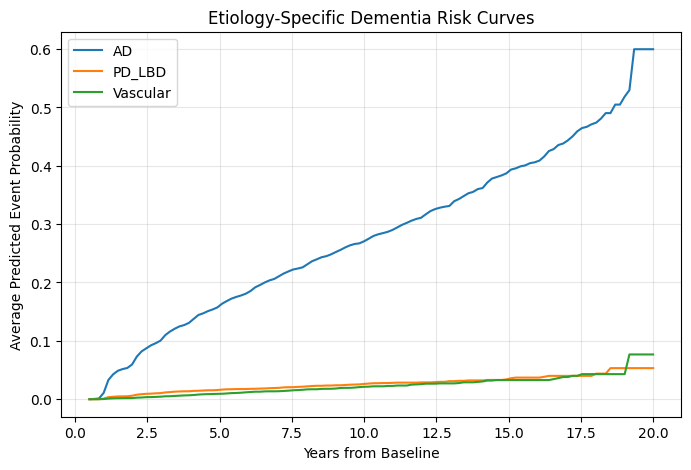

In [46]:
plt.figure(figsize=(8, 5))

for label in ["AD", "PD_LBD", "Vascular"]:
    if label in risk_curve_df.columns:
        plt.plot(risk_curve_df.index, risk_curve_df[label], label=label)

plt.xlabel("Years from Baseline")
plt.ylabel("Average Predicted Event Probability")
plt.title("Etiology-Specific Dementia Risk Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [47]:
milestone_years = [5, 10, 15]

etiology_risk_table = pd.DataFrame(index=milestone_years)

for label in risk_curve_df.columns:
    etiology_risk_table[label] = [
        float(risk_curve_df[label].iloc[np.argmin(np.abs(risk_curve_df.index - yr))])
        for yr in milestone_years
    ]

etiology_risk_table.index.name = "Years"
display(etiology_risk_table)

,AD,PD_LBD,Vascular
Years,,,
5,0.157285,0.015712,0.009192
10,0.270697,0.026243,0.021295
15,0.386938,0.033956,0.032834


Step 2 — Risk stratification survival curves

In [48]:
# Step 2: Risk stratification groups

if "analysis_df" not in globals():
    if "model_df" in globals() and "uncertainty_df" in globals():
        analysis_df = model_df.merge(
            uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score"]],
            on="NACCID",
            how="left"
        )
    else:
        raise ValueError("Need analysis_df or both model_df and uncertainty_df.")

# creaing risk groups using tertiles
analysis_df["risk_group_3"] = pd.qcut(
    analysis_df["risk_5y_mean"],
    q=3,
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(analysis_df["risk_group_3"].value_counts(dropna=False))

risk_group_3
Low Risk       9018
Medium Risk    9017
High Risk      9017
Name: count, dtype: int64


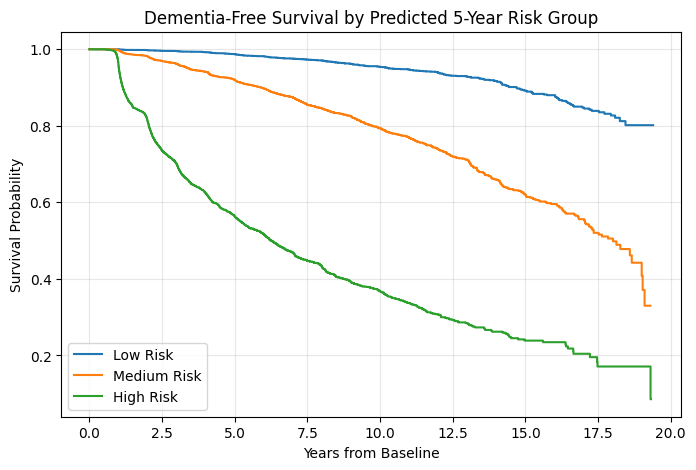

In [49]:
plt.figure(figsize=(8, 5))
kmf = KaplanMeierFitter()

for grp in ["Low Risk", "Medium Risk", "High Risk"]:
    tmp = analysis_df[analysis_df["risk_group_3"] == grp].copy()

    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Dementia-Free Survival by Predicted 5-Year Risk Group")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

In [50]:
risk_group_summary = analysis_df.groupby("risk_group_3").agg(
    n=("NACCID", "count"),
    mean_predicted_5y_risk=("risk_5y_mean", "mean"),
    observed_event_rate=("event_any_dementia", "mean"),
    mean_followup=("time_to_event", "mean")
)

display(risk_group_summary)

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/1494596913.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  risk_group_summary = analysis_df.groupby("risk_group_3").agg(


,n,mean_predicted_5y_risk,observed_event_rate,mean_followup
risk_group_3,,,,
Low Risk,9018,0.088484,0.031382,6.177708
Medium Risk,9017,0.138736,0.121659,5.563565
High Risk,9017,0.310902,0.384940,3.611746


Step 3 — Explain uncertainty

creates plots showing who becomes uncertain.

In [51]:
# Step 3: Uncertainty explanation

needed_cols = ["risk_5y_std", "confidence_score"]
for c in needed_cols:
    if c not in analysis_df.columns:
        raise ValueError(f"{c} not found in analysis_df")

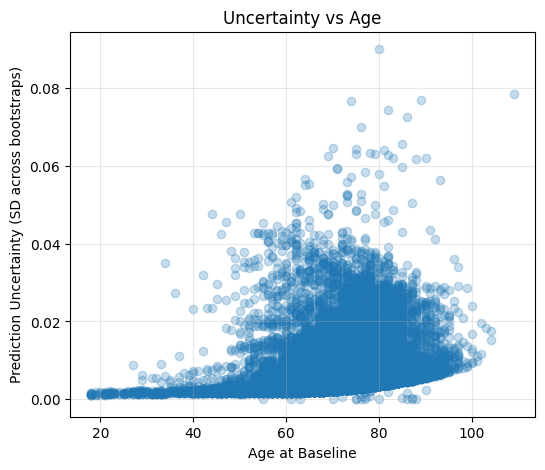

In [52]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["NACCAGE"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("Age at Baseline")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Age")
plt.grid(True, alpha=0.3)
plt.show()

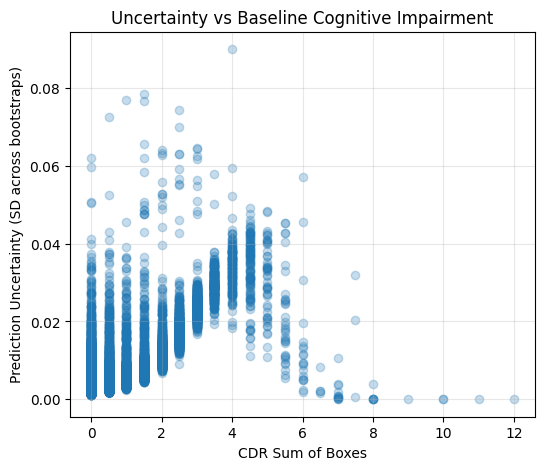

In [53]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["CDRSUM"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("CDR Sum of Boxes")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Baseline Cognitive Impairment")
plt.grid(True, alpha=0.3)
plt.show()

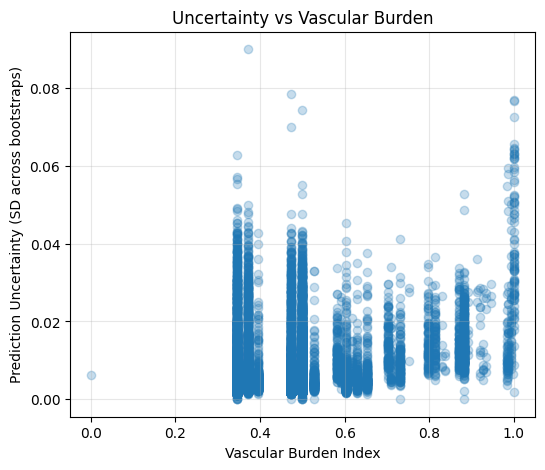

In [54]:
if "vascular_burden_index" in analysis_df.columns:
    plt.figure(figsize=(6, 5))
    plt.scatter(
        analysis_df["vascular_burden_index"],
        analysis_df["risk_5y_std"],
        alpha=0.25
    )
    plt.xlabel("Vascular Burden Index")
    plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
    plt.title("Uncertainty vs Vascular Burden")
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("vascular_burden_index not found in analysis_df")

In [55]:
def make_binned_summary(df, xcol, ycol="risk_5y_std", bins=5):
    tmp = df[[xcol, ycol]].dropna().copy()
    tmp["bin"] = pd.qcut(tmp[xcol], q=bins, duplicates="drop")
    out = tmp.groupby("bin").agg(
        n=(xcol, "count"),
        x_mean=(xcol, "mean"),
        y_mean=(ycol, "mean")
    )
    return out

display(make_binned_summary(analysis_df, "NACCAGE"))
display(make_binned_summary(analysis_df, "CDRSUM"))

if "vascular_burden_index" in analysis_df.columns:
    display(make_binned_summary(analysis_df, "vascular_burden_index"))

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(17.999, 64.0]",6073,57.403590,0.004623
"(64.0, 69.0]",5398,67.049278,0.005043
"(69.0, 74.0]",5815,71.938435,0.005861
"(74.0, 79.0]",4728,76.853426,0.007439
"(79.0, 109.0]",5038,84.209210,0.008857


/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(-0.001, 0.5]",20368,0.105239,0.004165
"(0.5, 1.0]",2275,1.000000,0.005803
"(1.0, 12.0]",4409,2.384101,0.016136


/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(-0.000254, 0.346]",8212,0.345954,0.005258
"(0.346, 0.371]",4739,0.370651,0.005777
"(0.371, 0.473]",4513,0.466964,0.005810
"(0.473, 0.5]",7488,0.499942,0.006253
"(0.5, 1.0]",2100,0.729312,0.012181


Step 4 — Age × vascular burden risk heatmap

In [56]:
# Step 4: Age x vascular burden risk landscape

# detecting main Cox model
main_cph = None
for name in ["cph", "cox_model", "cox_vbi", "cph_any"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using main Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find main Cox model. Rename main_cph manually.")

main_model_cols = list(main_cph.params_.index)

reference = {}
for col in main_model_cols:
    if col in analysis_df.columns:
        vals = pd.to_numeric(analysis_df[col], errors="coerce")
        if vals.notna().sum() > 0:
            reference[col] = float(vals.median())
        else:
            reference[col] = 0.0
    else:
        reference[col] = 0.0

if "SEX" in analysis_df.columns and "SEX" in reference:
    sex_mode = analysis_df["SEX"].mode()
    if len(sex_mode) > 0:
        reference["SEX"] = float(sex_mode.iloc[0])

age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

if "vascular_burden_index" not in analysis_df.columns:
    raise ValueError("vascular_burden_index not found in analysis_df")

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

grid_rows = []
for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = float(age)
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = float(vbi)
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[main_model_cols].copy()

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# predict 5-year risk
surv_grid = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y_grid = 1 - surv_grid.T.iloc[:, 0].values

risk_matrix = risk_5y_grid.reshape(len(age_grid), len(vbi_grid))

Using main Cox model: cph


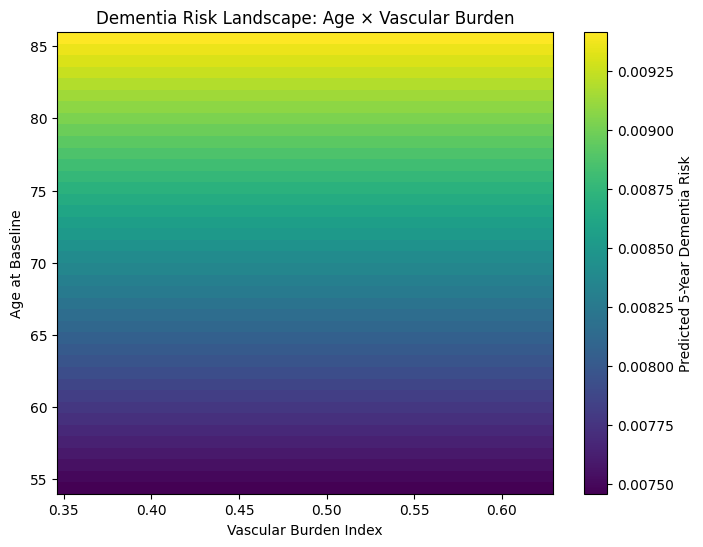

In [57]:
plt.figure(figsize=(8, 6))
im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[vbi_grid.min(), vbi_grid.max(), age_grid.min(), age_grid.max()]
)
plt.colorbar(im, label="Predicted 5-Year Dementia Risk")
plt.xlabel("Vascular Burden Index")
plt.ylabel("Age at Baseline")
plt.title("Dementia Risk Landscape: Age × Vascular Burden")
plt.show()

In [58]:
etiology_risk_table.to_csv("etiology_risk_table.csv")
risk_group_summary.to_csv("risk_group_summary.csv")

if "risk_curve_df" in globals():
    risk_curve_df.to_csv("etiology_risk_curves_full.csv")

print("Saved CSV outputs.")

Saved CSV outputs.
